# Large-Minibatch SGD and Gradual Warmup

## Introduction
For this part of the report, I would like to build upon my previous investigation of Stochastic Gradient Descent (SGD) and focus on how it behaves when training convolutional neural networks. In particular, I will be experimenting with different minibatch sizes, learning rates, and a technique known as gradual warmup. 

Using the CIFAR-100 dataset, I want to see how changing these parameters affects training time, convergence and model accuracy. I will also be exploring the mathematical reasoning behind linear learning-rate scaling and whether these techniques can make training more efficient without signifcantly affecting performance. I will also take the time to also perform an Exploratory Data Analysis on CIFAR-100 as a stepup from CIFAR-10 which I went over in the other part of the report. With all of that said, let's get started.

To begin, let's go over briefly the underlying mathematics behind what this part of the report is doing. Suppose that the training dataset contains $N$ labeled examples. The objective that the model has is to minimize the average loss, defined as

$$
L(\theta) = \frac{1}{N}\sum_{i=1}^{N} \ell(x_i, y_i; \theta)
$$

for
- $\theta$ represents the trainable parameters of the CNN
- $(x_i, y_i)$ represents a training image and its label
- $\ell$ measures the prediction error for an individual example.

Rather than comptuing the gradient over the entire dataset for every update, minibatch SGD estimates it using a subset $\mathcal{B}_t$:

$$
\boxed{\theta_{t + 1} = \theta_t - \eta \frac{1}{|\mathcal{B}_t|} \sum_{i \in \mathcal{B}_t} \nabla_{\theta}\ell(x_i, y_i; \theta_t)}
$$

This is the basic update without momentum; the experiments below use SGD with momentum. For $\eta$ is the learning rate, and $|\mathcal{B}_t|$ is the actual size of the current minibatch. Let $B$ denote the configured minibatch size. This minibatch size determines how many training examples contribute to each parameter update. For a dataset containing $N$ examples, the number of minibatches per epoch is:

$$
\boxed{S = \left\lceil \frac{N}{B} \right\rceil}
$$

The final minibatch may contain fewer than $B$ examples, and its gradient is averaged using its actual size. Full-batch gradient descent instead uses all $N$ training examples per update, giving one update per epoch. All tested batch sizes are smaller than $N$, so these experiments use minibatch SGD.

If $B$ is increased, then the number of updates per epoch is reduced, but it also increases the amount of data processed during each update. This introduces a tradeoff between computational efficiency and optimization behavior, which I will investigate through this notebook.

When increasing the minibatch size, one approach is to scale the learning rate proportionally as

$$
\eta(B) = \eta_0 \frac{B}{B_0}
$$

For $B_0 = 128$ and $\eta_0 = 0.01$ are the reference minibatch size and learning rate used here. This is known as the **linear scaling rule**, movtivated by approximating several smaller SGD updates with one larger update, assuming the gradients change little during those smaller updates. This is a heuristic rather than an exact equivalence, especially with momentum and batch normalization. To improve stability during the initial stages of training, we can also introduce *gradual warmup*, where the learning rate increases progressively toward its target value rather than starting at that value immediately. Both techniques will be investigated to determine whether or not they improve convergence when training with larger minibatches.

So now with the mathematics established, the questions now to answer are:
- How does minibatch size affect training efficiency?
- How does minibatch size affect the learning process?
- Can linear scaling and warmup improve large-minibatch training?

With all of that established, let's go ahead and officially start by loading up the data.

In [1]:
# General utilities
import os
import time
import math
import random
import shutil

# Numerical analysis and data visualization
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# PyTorch
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

# Dataset preparation
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import datasets, transforms
from PIL import Image
from torchvision.io import read_image, ImageReadMode


# Create a stratified training-validation split
from sklearn.model_selection import train_test_split

In [2]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"PyTorch Version: {torch.__version__}")
print(f"Device: {device}")

if device.type == "cuda":
  print(f"GPU: {torch.cuda.get_device_name(0)}")
  print(f"Available GPUs: {torch.cuda.device_count()}")

  gpu_memory = torch.cuda.get_device_properties(0).total_memory
  print(f"GPU Memory: {gpu_memory / (1024 ** 3):.2f} GB")

else:
  print("CUDA unavailable. Running on CPU.")

PyTorch Version: 2.11.0+cu128
Device: cuda
GPU: Tesla T4
Available GPUs: 2
GPU Memory: 14.56 GB


 For the data, we'll be using the CIFAR-100 dataset, which is a separate dataset in the same collection as CIFAR-10, which I previously worked with. While both datasets contain 60,000 images with a resolution of $32 \times 32$ pixels, CIFAR-100 contains 100 fine-grained classes compared to CIFAR-10's 10 classes, making image classification a more challenging task. Besides investigating the effects of minibatch size on SGD, I am also taking the time to explore this dataset with its larger number of classes. These experiments do not directly isolate the effect of class count, since they do not compare matched CIFAR-10 and CIFAR-100 training runs. All in all, this will allow me to build upon my previous work with CIFAR-10 while experimenting with a more complex classification problem. As reference, this dataset can be accessed on Kaggle [Here](https://www.kaggle.com/datasets/fedesoriano/cifar100)

In [3]:
from pathlib import Path
import pickle

DATA_DIR = Path("/kaggle/input/datasets/fedesoriano/cifar100")

# Dataset files
TRAIN_PATH = DATA_DIR / "train"
TEST_PATH = DATA_DIR / "test"
META_PATH = DATA_DIR / "meta"

# Load class metadata
with open(META_PATH, "rb") as f:
  metadata = pickle.load(f, encoding="bytes")

# Load fine and coarse class names
class_names = [
  name.decode("utf-8")
  for name in metadata[b"fine_label_names"]
]

coarse_class_names = [
  name.decode("utf-8")
  for name in metadata[b"coarse_label_names"]
]

# Map class identifiers to numerical labels
class_ids = list(range(len(class_names)))

class_to_idx = {
  class_name: idx
  for idx, class_name in enumerate(class_names)
}

# Verify dataset paths and metadata
required_paths = [
  TRAIN_PATH,
  TEST_PATH,
  META_PATH
]

paths_valid = all(path.is_file() for path in required_paths)
classes_valid = (
  len(class_ids) == len(class_to_idx) == len(class_names) == 100
  and len(coarse_class_names) == 20
)
labels_valid = all(name.strip() for name in class_names + coarse_class_names)

if paths_valid and classes_valid and labels_valid:
  print("CIFAR-100 setup: PASSED")
  print(f"Fine classes loaded: {len(class_names)}")
  print(f"Coarse classes loaded: {len(coarse_class_names)}")
  print("Training and test files: Ready")
  print("Class labels: Ready")
else:
  print("CIFAR-100 setup: FAILED")
  print("Missing files:", [str(path) for path in required_paths if not path.is_file()])
  print("Class metadata valid:", classes_valid and labels_valid)

CIFAR-100 setup: PASSED
Fine classes loaded: 100
Coarse classes loaded: 20
Training and test files: Ready
Class labels: Ready


## CIFAR-100 EDA

Going a bit deeper into CIFAR-100, this dataset contains 100 fine-grained image classes, with RGB images having a resolution of $32 \times 32$ pixels. Compared to CIFAR-10, which contains only 10 classes, CIFAR-100 presents a more challenging classification problem despite having the same number of images. This EDA will focus on verifying the dataset, examining its class distribution, visualizing sample images, and investigating how different minibatch sizes affect the composition of training data. These observations will help establish the context for the experiments involving batch size, optimization, and computational efficiency.

In [4]:
# Load CIFAR-100 training data
with open(TRAIN_PATH, "rb") as f:
  train_data = pickle.load(f, encoding="bytes")

# Extract images and fine-class labels
all_images = train_data[b"data"].reshape(-1, 3, 32, 32)
all_images = all_images.transpose(0, 2, 3, 1)

all_labels = np.array(train_data[b"fine_labels"])

train_images, val_images, train_labels, val_labels = train_test_split(
  all_images,
  all_labels,
  test_size=0.2,
  random_state=SEED,
  stratify=all_labels
)

# Verify image counts and class coverage
print(f"Training images: {len(train_images):,}")
print(f"Validation images: {len(val_images):,}")
print(f"Classes represented: {len(np.unique(train_labels))}")
print(
  f"Training images per class: "
  f"{np.bincount(train_labels).min()}–{np.bincount(train_labels).max()}"
)

Training images: 40,000
Validation images: 10,000
Classes represented: 100
Training images per class: 400–400


In [5]:
# Inspect a sample of training images
rng = np.random.default_rng(SEED)

sample_indices = rng.choice(
  len(train_images),
  size=100,
  replace=False
)

sample_images = train_images[sample_indices]

print(f"Image dimensions: {set(image.shape[:2] for image in sample_images)}")
print(f"Image channels: {set(image.shape[2] for image in sample_images)}")
print(f"Image data type: {sample_images.dtype}")
print(f"Sample size: {len(sample_indices)}")

Image dimensions: {(32, 32)}
Image channels: {3}
Image data type: uint8
Sample size: 100


Here, the official CIFAR-100 training set contains 50,000 images, with 500 images per fine-grained class. Using stratified sampling with a fixed seed, we split it into 40,000 training images and 10,000 validation images. This preserves 400 training images and 100 validation images per class, confirming that both subsets are balanced. The separate official test set contains 10,000 images and is not used in these experiments.

A random sample of 100 training images also confirmed the expected $32 \times 32$ resolution and three RGB channels. The images are already RGB, so no grayscale conversion or resizing is needed during preprocessing.


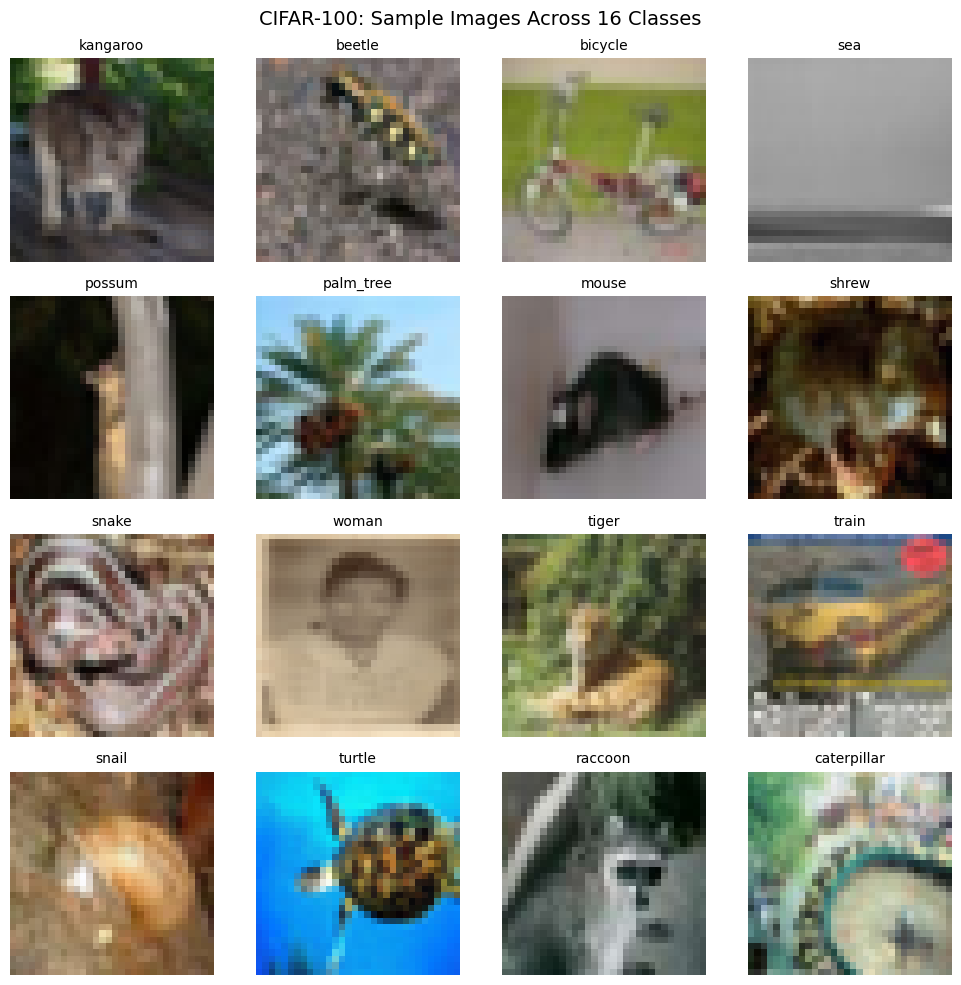

In [6]:
# Select 16 different classes
rng = np.random.default_rng(SEED)

selected_classes = rng.choice(len(class_ids), size=16, replace=False)

fig, axes = plt.subplots(4, 4, figsize=(10, 10))

for ax, class_idx in zip(axes.flat, selected_classes):
  # Find images belonging to the selected class
  class_indices = np.where(train_labels == class_idx)[0]
  image_idx = rng.choice(class_indices)

  # Load and display the image
  image = train_images[image_idx]
  ax.imshow(image)

  ax.set_title(class_names[class_idx], fontsize=10)
  ax.axis("off")

plt.suptitle("CIFAR-100: Sample Images Across 16 Classes", fontsize=14)
plt.tight_layout()
plt.show()

Here in this picture gallery, we can see the diversity of objects represented in CIFAR-100, ranging from animals and vehicles to everyday objects. Images also vary in their backgrounds, object positions, and visual complexity.

Despite the relatively small image resolution of $32 \times 32$ pixels, the CNN must learn to distinguish among 100 classes, including categories that may share similar visual features. Compared to CIFAR-10, which contains only 10 classes, CIFAR-100 presents a more challenging classification task while maintaining the same image resolution and dataset size. Therefore, this provides a useful setting for investigating how different minibatch sizes affect SGD training, model performance, and computational efficiency.

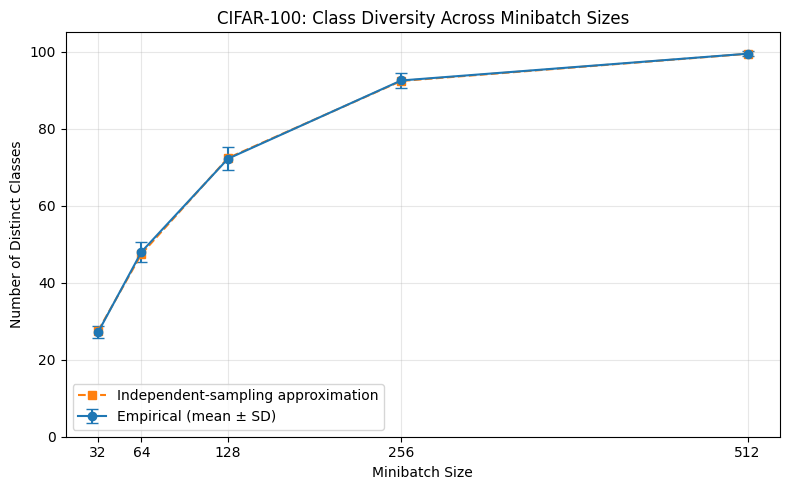

In [7]:
# Investigate class diversity across minibatch sizes
batch_sizes = [32, 64, 128, 256, 512]
num_trials = 100

rng = np.random.default_rng(SEED)

average_classes = []
std_classes = []

for batch_size in batch_sizes:
  distinct_counts = []

  for _ in range(num_trials):
    batch_labels = rng.choice(
      train_labels,
      size=batch_size,
      replace=False
    )

    distinct_counts.append(len(np.unique(batch_labels)))

  average_classes.append(np.mean(distinct_counts))
  std_classes.append(np.std(distinct_counts))

# Independent uniform-sampling approximation to sampling without replacement
expected_classes = [
  len(class_ids) * (1 - (1 - 1 / len(class_ids)) ** batch_size)
  for batch_size in batch_sizes
]

plt.figure(figsize=(8, 5))

plt.errorbar(
  batch_sizes,
  average_classes,
  yerr=std_classes,
  marker="o",
  capsize=4,
  label="Empirical (mean ± SD)"
)

plt.plot(
  batch_sizes,
  expected_classes,
  marker="s",
  linestyle="--",
  label="Independent-sampling approximation"
)

plt.title("CIFAR-100: Class Diversity Across Minibatch Sizes")
plt.xlabel("Minibatch Size")
plt.ylabel("Number of Distinct Classes")
plt.xticks(batch_sizes)
plt.ylim(0, 105)
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

The final thing to consider in this EDA is the minibatch composition. The following experiment examines how increasing minibatch size affects the number of distinct classes represented in a randomly sampled group of training images.

As minibatch size increases, more classes tend to appear within each batch, although the increase gradually slows because the dataset contains a fixed number of classes. The empirical results can also be compared with an independent uniform-sampling approximation. With $K = 100$ equally likely classes and $B$ independent draws with replacement, the expected number of distinct classes is

$$
\mathbb{E}[D_B] = K\left[1-\left(1-\frac{1}{K}\right)^B\right].
$$

Each class contributes the probability that it appears at least once. The actual experiment samples images without replacement from $N = 40{,}000$ balanced training examples, so the exact expectation is

$$
\mathbb{E}[D_B] = K\left[1-\frac{\binom{N-N/K}{B}}{\binom{N}{B}}\right].
$$

The plotted independent-sampling curve is an approximation because the sampled fraction is small. The error bars show the standard deviation across sampled minibatches, rather than uncertainty in the estimated mean. 

This provides an initial perspective on how minibatch size changes the composition of data used for each SGD update. However, class diversity alone doesn't determine the quality of the gradient estimate, so the effects on convergence and training efficiency will be investigated through the CNN experiments.

## Setting up the CNN Architecture and Testing Environment
Moving onto the CNN itself, it will consist of three convolutional blocks, with each block applying a $3 \times 3$ convolution, batch normalization, ReLU activation, and max pooling. The number of feature channels increases from 32 to 64 and finally 128 as the spatial dimensions decrease.

After the convolutional blocks, global average pooling reduces the feature maps to a feature vector, which is passed into a fully connected layer producing 100 class scores.

The architecture will remain fixed throughout our experiments so that the differences in training performance can be attributed primarily to the minibatch size and learning-rate strategies rather than changes in network structure.

In [8]:
class CIFAR100CNN(nn.Module):
  def __init__(self):
    super().__init__()

    self.features = nn.Sequential(
      # Block 1: 3 x 32 x 32 -> 32 x 16 x 16
      nn.Conv2d(3, 32, kernel_size=3, padding=1),
      nn.BatchNorm2d(32),
      nn.ReLU(),
      nn.MaxPool2d(kernel_size=2),

      # Block 2: 32 x 16 x 16 -> 64 x 8 x 8
      nn.Conv2d(32, 64, kernel_size=3, padding=1),
      nn.BatchNorm2d(64),
      nn.ReLU(),
      nn.MaxPool2d(kernel_size=2),

      # Block 3: 64 x 8 x 8 -> 128 x 4 x 4
      nn.Conv2d(64, 128, kernel_size=3, padding=1),
      nn.BatchNorm2d(128),
      nn.ReLU(),
      nn.MaxPool2d(kernel_size=2)
    )

    self.classifier = nn.Sequential(
      nn.AdaptiveAvgPool2d((1, 1)),
      nn.Flatten(),
      nn.Linear(128, 100)
    )

  def forward(self, x):
    x = self.features(x)
    x = self.classifier(x)
    return x

Mathematically, each convolutional block applies four operations: convolution, batch normalization, ReLU activation, and max pooling. Mathematically, this can be represented as

$$
X_{\ell+1}=\operatorname{MaxPool}\left(\operatorname{ReLU}\left(\operatorname{BN}\left(W_\ell*X_\ell+b_\ell\right)\right)\right)
$$

where $W_\ell*X_\ell$ represents convolution, $\operatorname{BN}$ normalizes the intermediate activations, ReLU introduces nonlinearity, and max pooling reduces the spatial dimensions while retaining prominent features.

After three convolutional blocks, global average pooling reduces the resulting feature maps into a vector of 128 features. The final fully connected layer computes

$$
z=W_{\mathrm{out}}h+b_{\mathrm{out}},\qquad z\in\mathbb{R}^{100}
$$

where $h\in\mathbb{R}^{128}$ is the extracted feature vector and $z$ contains the 100 class logits used for classification.

The same ReLU-based He initialization is applied to the convolutional and linear layers in every run as a common starting setting. It is motivated by approximate signal-scale preservation for rectifiers, rather than a guarantee of identical variances in this network with batch normalization and pooling. The architecture remains fixed across experiments to isolate the effects of minibatch size and learning-rate strategies.

In [9]:
# Initialize CNN weights
def initialize_model(model):
  for module in model.modules():
    if isinstance(module, (nn.Conv2d, nn.Linear)):
      nn.init.kaiming_normal_(
        module.weight,
        mode="fan_in",
        nonlinearity="relu"
      )

      if module.bias is not None:
        nn.init.zeros_(module.bias)

# Construct the model
torch.manual_seed(SEED)

model = CIFAR100CNN()
initialize_model(model)
model = model.to(device)

# Verify output dimensions
with torch.no_grad():
  sample_input = torch.randn(2, 3, 32, 32, device=device)
  sample_output = model(sample_input)

parameter_count = sum(
  p.numel() for p in model.parameters() if p.requires_grad
)

print(f"Device: {device}")
print(f"Input shape: {tuple(sample_input.shape)}")
print(f"Output shape: {tuple(sample_output.shape)}")
print(f"Trainable parameters: {parameter_count:,}")

Device: cuda
Input shape: (2, 3, 32, 32)
Output shape: (2, 100)
Trainable parameters: 106,596


Now that the CNN architecture is built and verified, let's prepare the images for training, and for the following experiments, the preprocessing of the data must be consistent across all minibatch experiments.

In terms of the images, the CNN expects input tensors of the shape

$$
(B, 3, 32, 32)
$$

For $B$ is the minibatch size. The custom dataset reads RGB image arrays and fine-class labels from the stratified split, and applies two transformations:
- Tensor conversion, changing channel order to $(3, 32, 32)$ and scaling integer pixel intensities from $[0, 255]$ to floating-point values in $[0, 1]$.
- Channel normalization using the CIFAR-100 means $(0.5071, 0.4867, 0.4408)$ and standard deviations $(0.2675, 0.2565, 0.2761)$ defined below.

For each channel $c$, normalization applies $x'_c = (x_c - \mu_c)/\sigma_c$. Training and validation use the same preprocessing, with no image augmentation or resizing.


In [10]:
from torchvision.transforms import functional as TF

image_transform = transforms.Compose([
  transforms.ToTensor(),
  transforms.Normalize(
    mean=[0.5071, 0.4867, 0.4408],
    std=[0.2675, 0.2565, 0.2761]
  )
])

In [11]:
class CIFAR100Dataset(Dataset):
  def __init__(self, images, labels, transform=None):
    self.images = images
    self.labels = labels
    self.transform = transform

  def __len__(self):
    return len(self.images)

  def __getitem__(self, idx):
    image = self.images[idx]
    label = int(self.labels[idx])

    if self.transform is not None:
      image = self.transform(image)

    return image, label


train_dataset = CIFAR100Dataset(
  train_images,
  train_labels,
  transform=image_transform
)

val_dataset = CIFAR100Dataset(
  val_images,
  val_labels,
  transform=image_transform
)

print(f"Training samples: {len(train_dataset):,}")
print(f"Validation samples: {len(val_dataset):,}")

Training samples: 40,000
Validation samples: 10,000


Verify the dataset returns the correctly shaped tensors and numerical labels

In [12]:
sample_image, sample_label = train_dataset[0]

print(f"Image shape: {tuple(sample_image.shape)}")
print(f"Image dtype: {sample_image.dtype}")
print(f"Training samples: {len(train_dataset):,}")
print(f"Validation samples: {len(val_dataset):,}")

Image shape: (3, 32, 32)
Image dtype: torch.float32
Training samples: 40,000
Validation samples: 10,000


Now that the images have been preprocessed, I'll use PyTorch's `DataLoader` to organize them into minibatches for training and validation. A `DataLoader` helps group the images into batches, shuffle training examples, and load images efficiently.

For the experiments, the batch size $B$ will be configurable, allowing me to investigate its effect on training performance without changing the CNN architecture. With $N = 40,000$ training images, the number of minibatches per epoch is

$$
S(B) = \left\lceil \frac{N}{B} \right\rceil
$$

with each minibatch generally corresponding to one SGD parameter update. Although larger minibatches reduce the number of SGD updates per epoch, each update requires processing more training samples. Let $N$ denote the number of training images, $B$ the minibatch size, and $C$ the computational cost of processing one image through the CNN.

Since each epoch requires approximately $\frac{N}{B}$ updates, with reach update costing $O(BC)$, the overal training complexity is 

$$
T(N,B,E)=O\left(E\cdot\frac{N}{B}\cdot BC\right)=\boxed{O(ENC)}.
$$

Here $E$ is the number of epochs. This counts the dominant per-image forward and backward work, leaving out per-update overhead, data loading, and hardware-dependent effects. Thus, for a fixed CNN architecture and number of epochs, the dominant arithmetic workload is approximately independent of minibatch size, but the number of optimizer updates is not.

However actual training time depends of GPU parallelism, memory usage, and computational overhead. During the experiments, the runtime will be measured across different minibatch sizes to investigate how these theoretical expectations compare with empirical performance.

In [13]:
def create_dataloaders(batch_size, seed=42):
  generator = torch.Generator().manual_seed(seed)

  train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,
    pin_memory=(device.type == "cuda"),
    generator=generator
  )

  val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
  )

  return train_loader, val_loader

To verify that this data loader function works, let's test it with a batch size of 128.

In [14]:
BATCH_SIZE = 128

train_loader, val_loader = create_dataloaders(BATCH_SIZE, seed=SEED)

images, labels = next(iter(train_loader))

print(f"Batch size: {BATCH_SIZE}")
print(f"Image batch shape: {tuple(images.shape)}")
print(f"Label batch shape: {tuple(labels.shape)}")
print(f"Training batches per epoch: {len(train_loader)}")
print(f"Validation batches: {len(val_loader)}")

Batch size: 128
Image batch shape: (128, 3, 32, 32)
Label batch shape: (128,)
Training batches per epoch: 313
Validation batches: 79


In [15]:
images, labels = next(iter(create_dataloaders(128)[0]))

print("Image batch:", images.shape)
print("Image dtype:", images.dtype)
print("Label batch:", labels.shape)
print("Dataset path:", TRAIN_PATH)

Image batch: torch.Size([128, 3, 32, 32])
Image dtype: torch.float32
Label batch: torch.Size([128])
Dataset path: /kaggle/input/datasets/fedesoriano/cifar100/train


And finally, let's see how increasing batch size reduces the number of SGD updates per epoch.

In [16]:
# Compare minibatch sizes and SGD updates
batch_sizes = [32, 64, 128, 256, 512]

batch_summary = pd.DataFrame({
  "Batch Size": batch_sizes,
  "SGD Updates per Epoch": [
    (len(train_dataset) + B - 1) // B
    for B in batch_sizes
  ]
})

display(batch_summary)

,Batch Size,SGD Updates per Epoch
0,32,1250
1,64,625
2,128,313
3,256,157
4,512,79


Here, the table demonstrates the inverse relationship between minibatch size and the number of SGD updates performed per epoch. As batch size increases, fewer updates process the entire training dataset. The ceiling accounts for the final, potentially smaller minibatch, since no examples are dropped.

However, fewer updates do not necessarily translate into proportionally faster training, since larger minibatches require more computation per update. This motivates our upcoming comparisons of actual training times and model performance.

The final part of setup is setting up two functions. One performs a complete training epoch using SGD with momentum. For each minibatch $\mathcal{B}_t$, define its average gradient as

$$
g_t = \frac{1}{|\mathcal{B}_t|}\sum_{i\in\mathcal{B}_t}\nabla_w\ell_i(w_t).
$$

With batch normalization, each $\ell_i$ here is evaluated using the statistics of the current minibatch, so it also depends on $\mathcal{B}_t$, not only on $w_t$ and example $i$.

The optimizer uses momentum $\mu = 0.9$, no weight decay, and no Nesterov correction. Starting from $v_{-1}=0$, its updates can be written as

$$
v_t = \mu v_{t-1}+g_t, \qquad w_{t+1}=w_t-\eta_t v_t.
$$

Where $\eta_t$ is the learning rate and $w_t$ represents the CNN's trainable parameters. Setting $\mu=0$ recovers the basic minibatch SGD update introduced earlier.

The other function evaluates the CNN without modifying its parameters or batch-normalization running statistics. Both functions return sample-weighted average cross-entropy loss and top-one accuracy:

$$
\text{Average Loss} = \frac{1}{M}\sum_{i=1}^{M}\ell_i, \qquad
\text{Accuracy} = \frac{\text{Correct Predictions}}{M}.
$$

Here $M$ is the number of examples in the relevant training or validation pass. Multiplying each minibatch's mean loss by its actual size before summing gives every example equal weight, including in a smaller final minibatch. Accuracy is stored as a fraction and multiplied by 100 for percentage plots. Training metrics combine predictions made as the model changes during the epoch; validation metrics use the fixed model at the end of that epoch. Batch normalization uses minibatch statistics during training and running statistics during validation, so these metrics are not measured under identical conditions.


In [17]:
def train_one_epoch(model, loader, optimizer, criterion, device):
  model.train()

  total_loss = 0.0
  correct = 0
  total = 0

  for images, labels in loader:
    images = images.to(device, non_blocking=True)
    labels = labels.to(device, non_blocking=True)

    optimizer.zero_grad(set_to_none=True)

    outputs = model(images)
    loss = criterion(outputs, labels)

    loss.backward()
    optimizer.step()

    batch_size = labels.size(0)

    total_loss += loss.item() * batch_size
    correct += (outputs.argmax(dim=1) == labels).sum().item()
    total += batch_size

  return total_loss / total, correct / total

def evaluate(model, loader, criterion, device):
  model.eval()

  total_loss = 0.0
  correct = 0
  total = 0

  with torch.inference_mode():
    for images, labels in loader:
      images = images.to(device, non_blocking=True)
      labels = labels.to(device, non_blocking=True)

      outputs = model(images)
      loss = criterion(outputs, labels)

      batch_size = labels.size(0)

      total_loss += loss.item() * batch_size
      correct += (outputs.argmax(dim=1) == labels).sum().item()
      total += batch_size

  return total_loss / total, correct / total

## Experimental Analysis: Large-Minibatch SGD
With the dataset, CNN architecture, and training pipeline established, it is now time to investigate how minibatch size influences the optimization process. In stochastic gradient descent (SGD), the minibatch size determines how many training examples contribute to each gradient estimate. Mathematically, this means:

$$
\nabla L_{\mathcal B}(w)=\frac{1}{|\mathcal B|}\sum_{i\in\mathcal B}\nabla\ell_i(w).
$$

For a fixed model and a loss that separates over examples, increasing a uniformly sampled minibatch generally reduces the sampling variance of the gradient estimate. Our CNN uses batch normalization, so each training example's output also depends on the other examples in its batch; changing batch size therefore changes normalization behavior as well. Larger minibatches also reduce the number of parameter updates per epoch and increase computation per update.

The experiments done will compare different minibatch sizes in terms of training loss, validation accuracy, and computational efficiency. We will also investigate whether learning-rate scaling and gradual warmup help maintain optimization performance when training with larger minibatches.

Before conducting these comparisons, let's perform a short test run that the training and validation functions operate correctly.

In [18]:
# Short training and validation sanity test

SANITY_BATCH_SIZE = 128
SANITY_TRAIN_SIZE = 1024
SANITY_VAL_SIZE = 256

torch.manual_seed(SEED)

sanity_train_dataset = Subset(
  train_dataset,
  torch.randperm(len(train_dataset))[:SANITY_TRAIN_SIZE].tolist()
)

sanity_val_dataset = Subset(
  val_dataset,
  torch.randperm(len(val_dataset))[:SANITY_VAL_SIZE].tolist()
)

sanity_train_loader = DataLoader(
  sanity_train_dataset,
  batch_size=SANITY_BATCH_SIZE,
  shuffle=True,
  num_workers=2,
  pin_memory=(device.type == "cuda")
)

sanity_val_loader = DataLoader(
  sanity_val_dataset,
  batch_size=SANITY_BATCH_SIZE,
  shuffle=False,
  num_workers=2,
  pin_memory=(device.type == "cuda")
)

sanity_model = CIFAR100CNN()
initialize_model(sanity_model)
sanity_model = sanity_model.to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.SGD(
  sanity_model.parameters(),
  lr=0.01,
  momentum=0.9
)

train_loss, train_acc = train_one_epoch(
  sanity_model,
  sanity_train_loader,
  optimizer,
  criterion,
  device
)

val_loss, val_acc = evaluate(
  sanity_model,
  sanity_val_loader,
  criterion,
  device
)

print(f"Training Loss: {train_loss:.4f}")
print(f"Training Accuracy: {train_acc:.2%}")
print(f"Validation Loss: {val_loss:.4f}")
print(f"Validation Accuracy: {val_acc:.2%}")

Training Loss: 5.2108
Training Accuracy: 0.68%
Validation Loss: 5.1265
Validation Accuracy: 1.17%


With the training and validation functions verified, we can now construct a reusable framework for evaluating different minibatch sizes.

For each experiment, the CNN will be initialized with the same architecture and seed, while the minibatch size and learning-rate configuration can be adjusted. The training/validation losses, classification accuracy, epoch runtime, and image throughput will be recorded.

Training throughput is defined as

$$
R(B)=\frac{N}{T_{\text{train}}(B)},
$$

Where $N$ is the number of training images and $T_{\text{train}}(B)$ is the measured training time for one epoch.

Training time includes data loading, transfers, forward and backward passes, and optimizer updates, with CUDA synchronization around the training pass. It excludes validation and model setup. Summary tables report final-epoch losses and accuracies, the arithmetic mean of epoch times and epoch throughputs, and the largest training-pass peak allocation. Mean epoch throughput is not necessarily the same as total examples divided by total training time.

The peak GPU memory allocation will also be recorded to investigate whether or not minibatch size affects memory requirements, and if so how big of an impact is it. This measures peak live PyTorch tensor allocation on the selected GPU in MiB, rather than total device memory or reserved allocator memory. Resetting the peak counter does not release existing tensors, so it can include other live notebook tensors, such as models from setup and sanity tests. These measurements will help evaluate performance and efficiency, with that memory baseline kept in mind.

In [19]:
def run_experiment(batch_size, learning_rate=0.01, epochs=3, seed=42):
  torch.manual_seed(seed)

  if device.type == "cuda":
    torch.cuda.manual_seed_all(seed)

  train_loader, val_loader = create_dataloaders(batch_size, seed=seed)

  model = CIFAR100CNN()
  initialize_model(model)
  model = model.to(device)

  criterion = nn.CrossEntropyLoss()

  optimizer = torch.optim.SGD(
    model.parameters(),
    lr=learning_rate,
    momentum=0.9
  )

  history = []

  for epoch in range(1, epochs + 1):
    if device.type == "cuda":
      torch.cuda.synchronize()
      torch.cuda.reset_peak_memory_stats(device)

    start = time.perf_counter()

    train_loss, train_acc = train_one_epoch(
      model, train_loader, optimizer, criterion, device
    )

    if device.type == "cuda":
      torch.cuda.synchronize()
      peak_memory = torch.cuda.max_memory_allocated(device) / (1024 ** 2)
    else:
      peak_memory = None

    train_time = time.perf_counter() - start

    val_loss, val_acc = evaluate(
      model, val_loader, criterion, device
    )

    history.append({
      "Epoch": epoch,
      "Batch Size": batch_size,
      "Learning Rate": learning_rate,
      "Training Loss": train_loss,
      "Training Accuracy": train_acc,
      "Validation Loss": val_loss,
      "Validation Accuracy": val_acc,
      "Training Time (s)": train_time,
      "Throughput (images/s)": len(train_dataset) / train_time,
      "Peak GPU Memory (MiB)": peak_memory
    })

  return pd.DataFrame(history)

Before testing all five minibatch sizes, let's run one baseline configuration to show whether the CNN's training loss decreases over multiple epochs and will provide an initial estimate of the runtime for future experiments. Keep in mind that the sanity run only went for 1 epoch.

In [20]:
baseline_history = run_experiment(
  batch_size=128,
  learning_rate=0.01,
  epochs=3,
  seed=SEED
)

display(baseline_history.round(4))

,Epoch,Batch Size,Learning Rate,Training Loss,Training Accuracy,Validation Loss,Validation Accuracy,Training Time (s),Throughput (images/s),Peak GPU Memory (MiB)
0,1,128,0.01,4.0596,0.0943,3.7606,0.1429,3.7027,10802.9844,108.624
1,2,128,0.01,3.5578,0.1693,3.4493,0.1849,3.7045,10797.7424,108.624
2,3,128,0.01,3.2839,0.2166,3.2671,0.2131,3.5321,11324.7729,108.624


Here, I trained the CIFAR-100 CNN using a minibatch size of 128, a learning rate of 0.01, and SGD with momentum for three epochs. The accompanying table shows how training and validation loss and accuracy change over this short run. Decreasing loss and improving accuracy indicate early learning progress, but three epochs do not establish convergence or the model's best achievable performance.

The table also provides measured epoch training times, throughput, and peak allocated GPU memory. These establish a reference point for comparing training efficiency, memory allocation, and model performance across minibatch sizes. The objective is to compare consistent settings rather than maximize classification accuracy.

## Experiment 1: Effect of Minibatch Size on SGD
With this benchmark, let's move onto the actual experimentation, where I'll train the model with varying minibatch sizes $(B = 32, 64, 128, 256, 512)$ and see how the sizes affect early learning progress and computational efficiency.


In [21]:
# Compare minibatch sizes with a fixed learning rate
batch_sizes = [32, 64, 128, 256, 512]

experiment_results = []

for batch_size in batch_sizes:
  print(f"Training with batch size {batch_size}...")

  if batch_size == 128:
    history = baseline_history.copy()
  else:
    history = run_experiment(
      batch_size=batch_size,
      learning_rate=0.01,
      epochs=3,
      seed=SEED
    )

  experiment_results.append(history)

comparison_history = pd.concat(
  experiment_results,
  ignore_index=True
)

print("Minibatch comparison completed.")

Training with batch size 32...
Training with batch size 64...
Training with batch size 128...
Training with batch size 256...
Training with batch size 512...
Minibatch comparison completed.


In [22]:
# Summarize final performance and computational efficiency
comparison_summary = (
  comparison_history
  .groupby("Batch Size")
  .agg({
    "Training Accuracy": "last",
    "Validation Accuracy": "last",
    "Training Loss": "last",
    "Validation Loss": "last",
    "Training Time (s)": "mean",
    "Throughput (images/s)": "mean",
    "Peak GPU Memory (MiB)": "max"
  })
  .reset_index()
)

comparison_summary["SGD Updates per Epoch"] = [
  (len(train_dataset) + B - 1) // B
  for B in comparison_summary["Batch Size"]
]

display(comparison_summary.round(4))

,Batch Size,Training Accuracy,Validation Accuracy,Training Loss,Validation Loss,Training Time (s),Throughput (images/s),Peak GPU Memory (MiB),SGD Updates per Epoch
0,32,0.2645,0.2730,2.9587,2.9433,5.7248,6987.3598,42.9619,1250
1,64,0.2478,0.2503,3.0796,3.0561,3.9606,10100.1128,64.7241,625
2,128,0.2166,0.2131,3.2839,3.2671,3.6464,10975.1665,108.6240,313
3,256,0.1723,0.1846,3.5672,3.5092,2.8011,14286.0858,196.1738,157
4,512,0.1319,0.1403,3.8370,3.7941,2.9398,13609.4239,690.3442,79


Here, the summary table and Figure A compare classification performance under a fixed learning rate over the same three-epoch training budget. When smaller minibatches reach higher accuracy or lower loss, this is an early-training result under these settings, rather than evidence that they always produce better final models. The curves show whether progress continues across epochs, but this short run does not establish convergence.

One important difference is the number of SGD updates. With 40,000 training images, a minibatch size of 32 gives 1,250 updates per epoch, while a minibatch size of 512 gives 79 updates. All configurations process the same number of training examples, but smaller minibatches update the parameters more often. Batch normalization also depends on minibatch composition, so this comparison does not isolate gradient noise alone.

The summary table and Figure B show the computational side of this tradeoff. Larger minibatches can make better use of GPU parallelism and reduce overhead per image, but their actual speed advantage must be read from the measured epoch times and throughput. Throughput need not increase monotonically with batch size: a plateau or decrease can reflect hardware limits, kernel choices, or timing variability. A single short run cannot identify the cause, and proportional speed improvements are not guaranteed. Larger batches generally require more tensor storage, while reported peak allocation also includes the notebook's existing live GPU tensors.


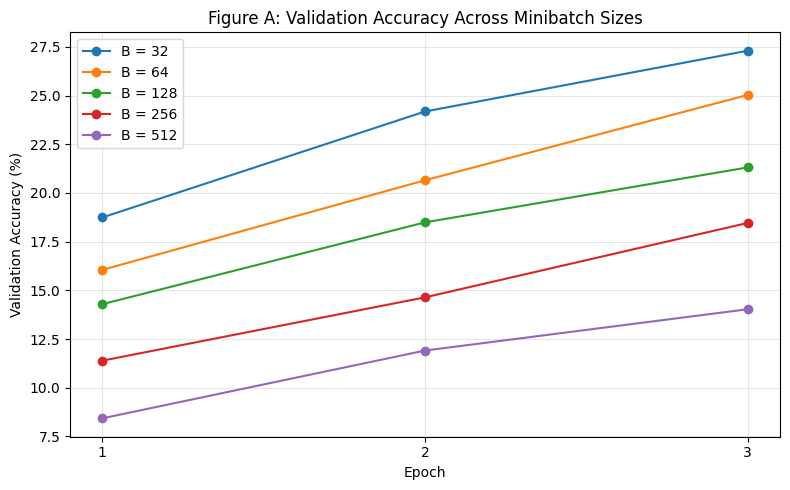

In [23]:
plt.figure(figsize=(8, 5))

for batch_size in batch_sizes:
  history = comparison_history[
    comparison_history["Batch Size"] == batch_size
  ]

  plt.plot(
    history["Epoch"],
    history["Validation Accuracy"] * 100,
    marker="o",
    label=f"B = {batch_size}"
  )

plt.title("Figure A: Validation Accuracy Across Minibatch Sizes")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy (%)")
plt.xticks([1, 2, 3])
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

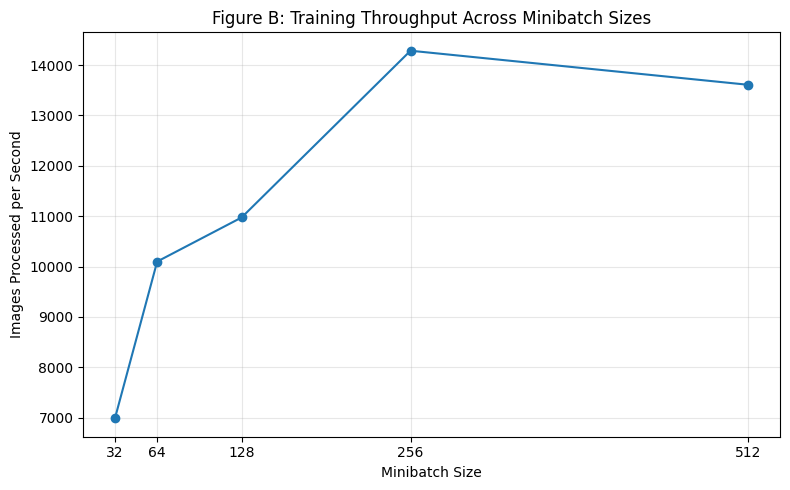

In [24]:
plt.figure(figsize=(8, 5))

plt.plot(
  comparison_summary["Batch Size"],
  comparison_summary["Throughput (images/s)"],
  marker="o"
)

plt.title("Figure B: Training Throughput Across Minibatch Sizes")
plt.xlabel("Minibatch Size")
plt.ylabel("Images Processed per Second")
plt.xticks(batch_sizes)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Overall, this experiment evaluates the tradeoff between early classification performance and computational efficiency when changing minibatch size. If larger minibatches provide higher throughput but lower validation accuracy, they process the training examples faster without necessarily making the same learning progress within the fixed epoch budget. The table and plots show the size of this tradeoff for the current run.

These comparisons use equal numbers of processed examples, rather than equal numbers of optimizer updates. Increasing minibatch size alone therefore does not guarantee a better overall training process. In the next experiment, I will investigate whether adjusting learning rate alongside minibatch size changes early learning progress while retaining any computational advantages.

## Experiment 2: Linear Learning-Rate Scaling
Moving onto the next experiment, let's investigate scaling the learning rate proportionally to minibatch size, using

$$
\eta(B)=0.01\frac{B}{128}.
$$

This lowers the learning rate below the reference batch size and raises it above the reference. The idea is to approximately compensate for fewer updates with larger minibatches, assuming gradients change little between the smaller updates being approximated. Momentum and batch normalization make this an imperfect equivalence, so improved accuracy or stability is not guaranteed. At the reference batch size of 128, the existing baseline history is reused, so its results are identical by construction.

With that being said, let's do this experiment.


In [25]:
# Compare minibatch sizes using linear learning-rate scaling
REFERENCE_BATCH_SIZE = 128
REFERENCE_LEARNING_RATE = 0.01

scaled_results = []

for batch_size in batch_sizes:
  scaled_lr = (
    REFERENCE_LEARNING_RATE
    * batch_size / REFERENCE_BATCH_SIZE
  )

  print(f"Training B = {batch_size}, LR = {scaled_lr:.4f}")

  if batch_size == REFERENCE_BATCH_SIZE:
    history = baseline_history.copy()
  else:
    history = run_experiment(
      batch_size=batch_size,
      learning_rate=scaled_lr,
      epochs=3,
      seed=SEED
    )

  scaled_results.append(history)

scaled_history = pd.concat(
  scaled_results,
  ignore_index=True
)

print("Learning-rate scaling experiment completed.")

Training B = 32, LR = 0.0025
Training B = 64, LR = 0.0050
Training B = 128, LR = 0.0100
Training B = 256, LR = 0.0200
Training B = 512, LR = 0.0400
Learning-rate scaling experiment completed.


In [26]:
# Summarize linear learning-rate scaling results
scaled_summary = (
  scaled_history
  .groupby("Batch Size")
  .agg({
    "Learning Rate": "first",
    "Training Accuracy": "last",
    "Validation Accuracy": "last",
    "Training Loss": "last",
    "Validation Loss": "last",
    "Training Time (s)": "mean",
    "Throughput (images/s)": "mean",
    "Peak GPU Memory (MiB)": "max"
  })
  .reset_index()
)

display(scaled_summary.round(4))

,Batch Size,Learning Rate,Training Accuracy,Validation Accuracy,Training Loss,Validation Loss,Training Time (s),Throughput (images/s),Peak GPU Memory (MiB)
0,32,0.0025,0.2106,0.2241,3.3170,3.2195,5.7734,6928.8998,42.9619
1,64,0.0050,0.2151,0.2166,3.2876,3.2475,3.9958,10011.0664,64.7241
2,128,0.0100,0.2166,0.2131,3.2839,3.2671,3.6464,10975.1665,108.6240
3,256,0.0200,0.2113,0.2016,3.3081,3.3139,2.8420,14085.1787,196.1738
4,512,0.0400,0.2024,0.1904,3.3525,3.4456,2.5834,15492.3078,690.3442


From the results, we can compare how proportional learning-rate scaling changes early training at each minibatch size. For smaller minibatches, the scaled learning rate is below the fixed reference rate. If their loss decreases more slowly or validation accuracy is lower, the smaller step size may be limiting progress within the short training budget. For larger minibatches, a higher learning rate may partly compensate for fewer updates, but it may also introduce instability.

The summary table reports observed performance alongside training time, throughput, and peak allocation. Changing only the learning rate does not change tensor shapes or the number of examples processed, so similar computational costs are expected for corresponding batch sizes. Measured timing differences should still be interpreted in light of runtime variability. The next table compares the accuracy effects directly against the fixed-learning-rate experiment.


In [27]:
# Compare final validation accuracy between experiments
lr_comparison = comparison_summary[
  ["Batch Size", "Validation Accuracy"]
].rename(
  columns={"Validation Accuracy": "Fixed LR"}
)

lr_comparison = lr_comparison.merge(
  scaled_summary[["Batch Size", "Validation Accuracy"]].rename(
    columns={"Validation Accuracy": "Scaled LR"}
  ),
  on="Batch Size"
)

lr_comparison["Accuracy Difference"] = (
  lr_comparison["Scaled LR"] - lr_comparison["Fixed LR"]
)

display(lr_comparison.round(4))

,Batch Size,Fixed LR,Scaled LR,Accuracy Difference
0,32,0.2730,0.2241,-0.0489
1,64,0.2503,0.2166,-0.0337
2,128,0.2131,0.2131,0.0000
3,256,0.1846,0.2016,0.0170
4,512,0.1403,0.1904,0.0501


Comparing these results to Experiment 1, the table shows final validation accuracy for each strategy and their difference. A positive difference favors scaling in the current run, while a negative difference favors the fixed learning rate. These differences are stored as accuracy fractions; multiplying them by 100 expresses the change in percentage points.

For batch sizes below 128, scaling reduces the learning rate, while above 128 it increases it. This distinguishes the effect of taking smaller steps from the intended compensation for fewer large-minibatch updates. At batch size 128, both columns reuse the same baseline result, rather than provide independent evidence of reproducibility.

The following graph makes these comparisons easier to see across batch sizes. Any improvement describes early training under the tested settings; a single run does not establish that either learning-rate strategy is universally better.


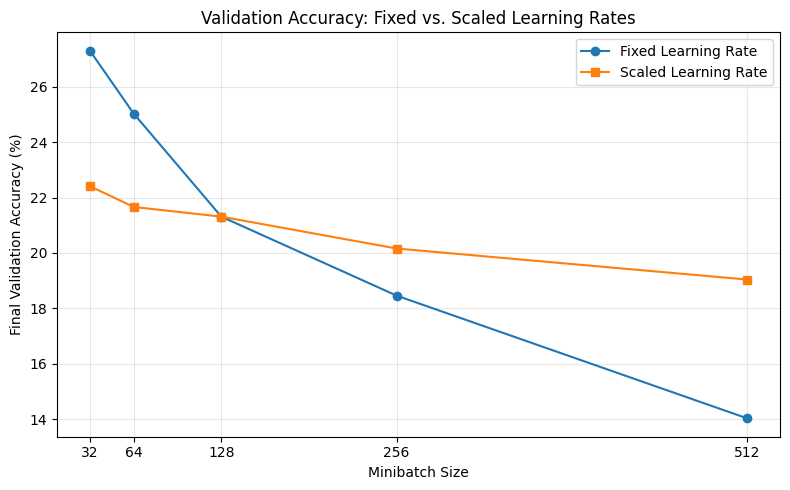

In [28]:
plt.figure(figsize=(8, 5))

plt.plot(
  lr_comparison["Batch Size"],
  lr_comparison["Fixed LR"] * 100,
  marker="o",
  label="Fixed Learning Rate"
)

plt.plot(
  lr_comparison["Batch Size"],
  lr_comparison["Scaled LR"] * 100,
  marker="s",
  label="Scaled Learning Rate"
)

plt.title("Validation Accuracy: Fixed vs. Scaled Learning Rates")
plt.xlabel("Minibatch Size")
plt.ylabel("Final Validation Accuracy (%)")
plt.xticks(batch_sizes)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

Overall, Experiment 2 tests whether proportional learning-rate scaling improves early learning progress for larger minibatches while retaining their computational advantages. Where scaling gives better validation performance, it suggests that adjusting step size can help within this training budget. Where it does not, linear scaling alone is insufficient under the tested settings. Starting immediately at a larger target learning rate can also make early optimization less stable, although that possibility should not be treated as an observed failure without supporting loss curves.

## Experiment 3: Gradual Learning-rate Warmup
This leads us to our final experiment, where we will investigate gradual learning-rate warmup. Rather than starting at the full scaled learning rate, we increase it during the first epoch, then keep it at the target for the remaining two epochs. The goal is to test whether this gentler start changes early loss and validation performance compared with scaling alone; warmup is not guaranteed to improve accuracy.

With $S=\lceil N/B\rceil$ updates per epoch, target rate $\eta_{\mathrm{target}}=0.01B/128$, and global update number $t=1,2,\ldots$, the implemented schedule is

$$
\eta_t=\eta_{\mathrm{target}}\min\left(\frac{t}{S},1\right).
$$

The first update uses $\eta_{\mathrm{target}}/S$, rather than zero or the reference rate. The target is reached on the last update of the first epoch. Thus, warmup spans the same number of processed examples at each batch size, but a different number of updates. The table's Learning Rate column records the target rate, rather than every intermediate warmup value.


In [29]:
def train_one_epoch_warmup(
  model, loader, optimizer, criterion, device,
  target_lr, warmup_steps, global_step
):
  model.train()

  total_loss = 0.0
  correct = 0
  total = 0

  for images, labels in loader:
    images = images.to(device, non_blocking=True)
    labels = labels.to(device, non_blocking=True)

    global_step += 1

    current_lr = target_lr * min(
      global_step / warmup_steps, 1.0
    )

    for group in optimizer.param_groups:
      group["lr"] = current_lr

    optimizer.zero_grad(set_to_none=True)

    outputs = model(images)
    loss = criterion(outputs, labels)

    loss.backward()
    optimizer.step()

    batch_size = labels.size(0)

    total_loss += loss.item() * batch_size
    correct += (outputs.argmax(dim=1) == labels).sum().item()
    total += batch_size

  return total_loss / total, correct / total, global_step

def run_warmup_experiment(batch_size, epochs=3, seed=42):
  torch.manual_seed(seed)

  if device.type == "cuda":
    torch.cuda.manual_seed_all(seed)

  train_loader, val_loader = create_dataloaders(batch_size, seed=seed)

  target_lr = 0.01 * batch_size / 128
  warmup_steps = len(train_loader)
  global_step = 0

  model = CIFAR100CNN()
  initialize_model(model)
  model = model.to(device)

  criterion = nn.CrossEntropyLoss()

  optimizer = torch.optim.SGD(
    model.parameters(),
    lr=target_lr,
    momentum=0.9
  )

  history = []

  for epoch in range(1, epochs + 1):
    if device.type == "cuda":
      torch.cuda.synchronize()
      torch.cuda.reset_peak_memory_stats(device)

    start = time.perf_counter()

    train_loss, train_acc, global_step = train_one_epoch_warmup(
      model,
      train_loader,
      optimizer,
      criterion,
      device,
      target_lr,
      warmup_steps,
      global_step
    )

    if device.type == "cuda":
      torch.cuda.synchronize()
      peak_memory = torch.cuda.max_memory_allocated(device) / (1024 ** 2)
    else:
      peak_memory = None

    train_time = time.perf_counter() - start

    val_loss, val_acc = evaluate(
      model, val_loader, criterion, device
    )

    history.append({
      "Epoch": epoch,
      "Batch Size": batch_size,
      "Learning Rate": target_lr,
      "Training Loss": train_loss,
      "Training Accuracy": train_acc,
      "Validation Loss": val_loss,
      "Validation Accuracy": val_acc,
      "Training Time (s)": train_time,
      "Throughput (images/s)": len(train_dataset) / train_time,
      "Peak GPU Memory (MiB)": peak_memory
    })

  return pd.DataFrame(history)

In [30]:
# Compare gradual warmup for larger minibatches
warmup_batch_sizes = [256, 512]

warmup_results = []

for batch_size in warmup_batch_sizes:
  print(f"Training with warmup: B = {batch_size}")

  history = run_warmup_experiment(
    batch_size=batch_size,
    epochs=3,
    seed=SEED
  )

  warmup_results.append(history)

warmup_history = pd.concat(
  warmup_results,
  ignore_index=True
)

print("Gradual warmup experiment completed.")

Training with warmup: B = 256
Training with warmup: B = 512
Gradual warmup experiment completed.


In [31]:
warmup_summary = (
  warmup_history
  .groupby("Batch Size")
  .agg({
    "Learning Rate": "first",
    "Training Accuracy": "last",
    "Validation Accuracy": "last",
    "Training Loss": "last",
    "Validation Loss": "last",
    "Training Time (s)": "mean",
    "Throughput (images/s)": "mean",
    "Peak GPU Memory (MiB)": "max"
  })
  .reset_index()
)

display(warmup_summary.round(4))

,Batch Size,Learning Rate,Training Accuracy,Validation Accuracy,Training Loss,Validation Loss,Training Time (s),Throughput (images/s),Peak GPU Memory (MiB)
0,256,0.02,0.1977,0.1890,3.3906,3.3748,2.8753,13920.6175,196.1738
1,512,0.04,0.1912,0.1974,3.4214,3.4097,2.8889,13847.1806,690.3442


The table reports the outcomes of one-epoch warmup for the two larger minibatch sizes. Their final losses and validation accuracies show how much early learning progress each configuration makes, while the timing and allocation columns show its computational cost. A larger batch still performs fewer updates per epoch, so differences between these rows cannot be attributed to warmup alone.

Warmup changes step sizes without changing the architecture or batch dimensions, so similar computational requirements are expected relative to scaling alone at the same batch size. To evaluate its additional effect, the following table compares fixed learning rates, linear scaling, and gradual warmup separately for each batch size.


In [32]:
warmup_comparison = (
  comparison_summary[
    ["Batch Size", "Validation Accuracy"]
  ]
  .rename(columns={
    "Validation Accuracy": "Fixed LR"
  })
  .merge(
    scaled_summary[
      ["Batch Size", "Validation Accuracy"]
    ].rename(columns={
      "Validation Accuracy": "Scaled LR"
    }),
    on="Batch Size"
  )
  .merge(
    warmup_summary[
      ["Batch Size", "Validation Accuracy"]
    ].rename(columns={
      "Validation Accuracy": "Warmup"
    }),
    on="Batch Size"
  )
)

display(
  warmup_comparison[
    warmup_comparison["Batch Size"].isin(warmup_batch_sizes)
  ].round(4)
)

,Batch Size,Fixed LR,Scaled LR,Warmup
0,256,0.1846,0.2016,0.1890
1,512,0.1403,0.1904,0.1974


Comparing the results of all three experiments, the table shows whether linear scaling and warmup improve validation accuracy relative to the fixed-learning-rate baseline at each larger minibatch size. Warmup should also be compared directly with scaling alone, since they share the same target rate and differ in the first-epoch schedule.

If warmup scores lower, its gentler start may have delayed progress within the three-epoch budget. If it scores higher, this is consistent with a beneficial early schedule in that run, but does not by itself demonstrate improved stability or a reliable accuracy advantage. Small differences require repeated runs before drawing strong conclusions.

The following bar chart summarizes these comparisons. The ordering of methods may differ between batch sizes or executions, so the main question is whether the first-epoch schedule changes the balance between early learning progress and computational cost under the tested settings.


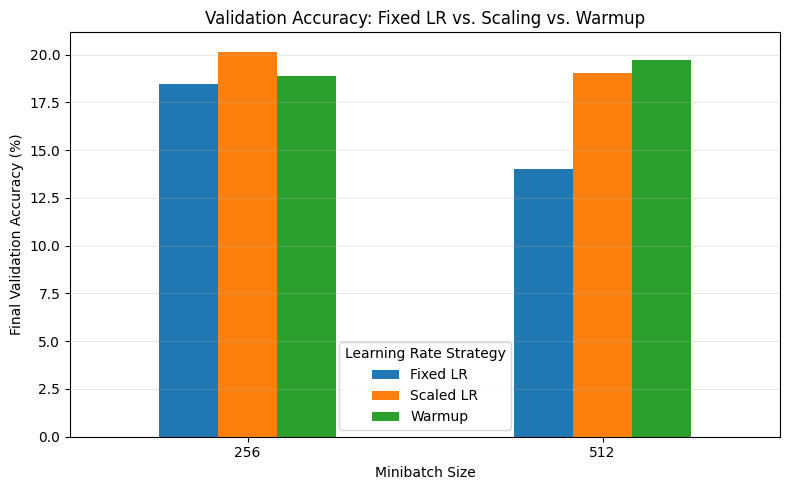

In [33]:
warmup_plot = warmup_comparison[
  warmup_comparison["Batch Size"].isin(warmup_batch_sizes)
].set_index("Batch Size")

ax = (
  warmup_plot[["Fixed LR", "Scaled LR", "Warmup"]] * 100
).plot(
  kind="bar",
  figsize=(8, 5),
  rot=0
)

ax.set_title("Validation Accuracy: Fixed LR vs. Scaling vs. Warmup")
ax.set_xlabel("Minibatch Size")
ax.set_ylabel("Final Validation Accuracy (%)")
ax.grid(axis="y", alpha=0.3)
ax.legend(title="Learning Rate Strategy")

plt.tight_layout()
plt.show()

## Final Conclusions, Thoughts, and Limitations
Throughout this report, I investigated how minibatch size and learning-rate strategies affect the training performance and computational efficiency of a convolutional neural network using the CIFAR-100 dataset. The experiments focused on three approaches: comparing different minibatch sizes under a fixed learning rate, applying linear learning-rate scaling, and introducing gradual learning-rate warmup.

Experiment 1 compares early learning progress and hardware efficiency over the same number of processed examples. Smaller minibatches perform more parameter updates, while larger minibatches can use GPU parallelism more efficiently. The tables and graphs show whether a throughput advantage comes with a loss in validation performance in the current run. Neither the fastest configuration nor the most accurate after three epochs is necessarily the best choice for longer training.

Experiment 2 investigates whether adjusting learning rate proportionally to minibatch size changes that tradeoff. Scaling lowers the step size below the reference batch size and raises it above the reference. Any improvement for larger minibatches suggests that step size helps compensate for fewer updates under these settings, but this approximate rule does not guarantee matching accuracy or stable optimization across batch sizes.

Finally, Experiment 3 compares a one-epoch warmup with immediate scaling for the two largest minibatches. Its effect should be judged separately at each batch size using the comparison table and graph. Warmup may help, hurt, or make little difference within this short budget, and a small accuracy advantage in one run does not establish a consistent benefit.

Overall, these experiments show how to evaluate training efficiency alongside learning progress. Throughput and epoch time describe how quickly examples are processed, while validation loss and accuracy describe the resulting model. Equal numbers of processed examples do not imply equal numbers of optimizer updates, and a useful configuration must balance these measures rather than maximize throughput alone.

While the experiments provided useful observations about large-minibatch SGD, there are several limitations worth considering.
- Limited training duration: Each CNN was trained for only three epochs. These results describe early training behavior and do not establish convergence or best achievable performance. Longer runs would help evaluate that distinction.
- Fixed number of epochs: All configurations processed the same number of training examples, but smaller minibatches performed substantially more SGD updates. Comparisons with matched update counts or wall-clock budgets would answer different questions and help separate these effects.
- Simplified CNN architecture: The experiments used a small CNN with three convolutional blocks. Batch normalization depends on minibatch statistics, so changing batch size affects normalization as well as gradient estimation. Different architectures or normalization methods could change the results.
- Limited learning-rate schedules: Linear scaling used a reference batch size of 128 and reference learning rate of 0.01, while warmup lasted one complete epoch. Other target rates, warmup durations, and later schedules could produce different results.
- Single experimental runs: Each configuration used one fixed seed, with matching initialization and seeded training-data shuffling. Reusing the reference baseline gives identical reference results by construction. Independent seeds are needed to measure variability, and fixed seeds alone do not guarantee deterministic CUDA execution.
- Measurement limits: Timing includes the training pass and data-loading overhead, but excludes validation and model setup. Short runs are sensitive to startup costs and hardware load. Peak allocated GPU memory includes other live notebook tensors, so isolated measurements would require releasing unrelated allocations or using a fresh process. These runs use one GPU, even when Kaggle exposes more than one, and do not measure distributed scaling.
- Validation scope: Only the stratified training and validation subsets are used. The official test set remains unused, so the notebook does not report held-out test performance.

Overall as a personal reflection, these experiments helped me see behind the computational efficiency of CNNs, as while the other part of the report explores more on the architecture, this one explores how the specific hyperparameters can affect the performance of the model. And so walking out of both experiments, they all helped me in understanding how CNNs work generally.

For reference, this part of the report is based on the 2017 paper [Accurate, Large Minibatch SGD: Training ImageNet in 1 Hour.](https://arxiv.org/abs/1706.02677) by Priya Goyal et al.
